In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.metrics import RocCurveDisplay

print("✅ Libraries loaded!")

✅ Libraries loaded!


In [2]:
df = pd.read_excel('data/online_retail_II.xlsx')
print("Raw shape:", df.shape)

# Clean
df = df.dropna(subset=['Customer ID'])
df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]
df['TotalSpend'] = df['Quantity'] * df['Price']

print("Clean shape:", df.shape)
print(df.head())

Raw shape: (525461, 8)
Clean shape: (407664, 9)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  TotalSpend  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom        83.4  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom        81.0  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom        81.0  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom       100.8  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom        30.0  


In [3]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency = ('Invoice', 'nunique'),
    Monetary  = ('TotalSpend', 'sum')
).reset_index()

print("RFM Shape:", rfm.shape)
print(rfm.describe())

RFM Shape: (4312, 4)
        Customer ID      Recency    Frequency       Monetary
count   4312.000000  4312.000000  4312.000000    4312.000000
mean   15349.290353    91.171846     4.455705    2048.238236
std     1701.200176    96.860633     8.170213    8914.481280
min    12346.000000     1.000000     1.000000       2.950000
25%    13882.500000    18.000000     1.000000     307.987500
50%    15350.500000    53.000000     2.000000     706.020000
75%    16834.250000   136.000000     5.000000    1723.142500
max    18287.000000   374.000000   205.000000  349164.350000


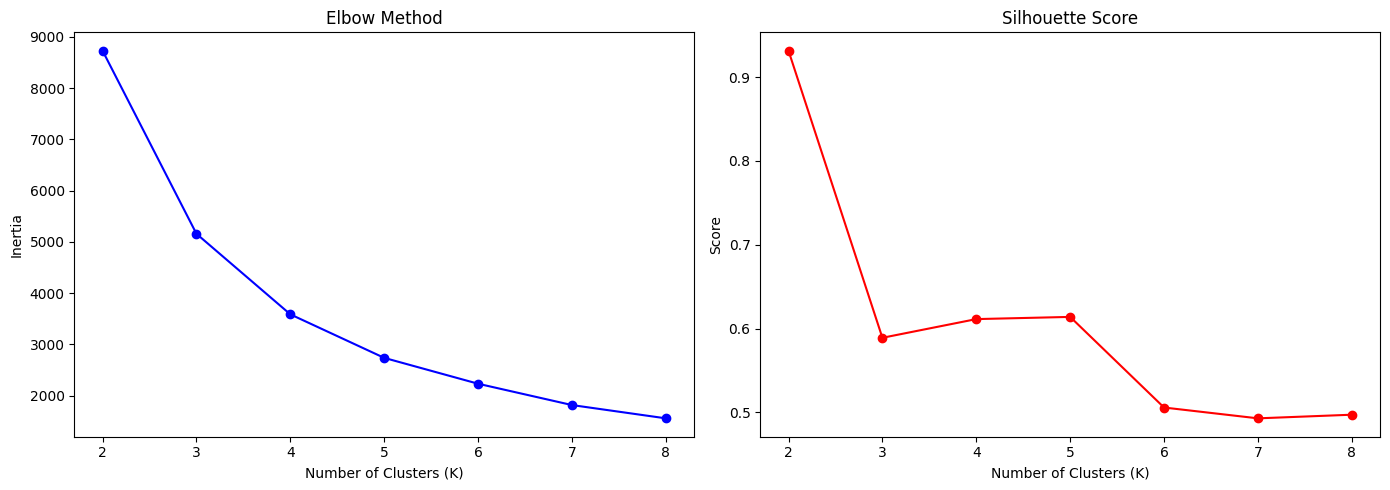

✅ Done! Look at the plots to pick the best K


In [4]:
# Scale RFM features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

# Find best number of clusters using Elbow Method
inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(rfm_scaled, km.labels_))

# Plot Elbow + Silhouette
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouettes, 'ro-')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.savefig('elbow_silhouette.png', dpi=150)
plt.show()
print("✅ Done! Look at the plots to pick the best K")

In [5]:
# Apply KMeans with K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Analyze each cluster
cluster_summary = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(1)
print("=== Cluster Summary ===")
print(cluster_summary)

# Count customers per cluster
print("\n=== Customers per Cluster ===")
print(rfm['Cluster'].value_counts().sort_index())

=== Cluster Summary ===
         Recency  Frequency  Monetary
Cluster                              
0           43.1        4.4    1710.8
1          243.0        1.7     596.9
2            5.6      113.6  215543.7
3           14.3       46.0   28018.4

=== Customers per Cluster ===
Cluster
0    3201
1    1047
2       5
3      59
Name: count, dtype: int64


In [8]:
cluster_labels = {
    0: 'At-Risk',
    1: 'Lost',
    2: 'VIP',
    3: 'Loyal'
}

rfm['Segment'] = rfm['Cluster'].map(cluster_labels)
print("=== Segment Distribution ===")
print(rfm['Segment'].value_counts())
print(rfm.head(10))

=== Segment Distribution ===
Segment
At-Risk    3201
Lost       1047
Loyal        59
VIP           5
Name: count, dtype: int64
   Customer ID  Recency  Frequency  Monetary  Cluster  Segment
0      12346.0      165         11    372.86        1     Lost
1      12347.0        3          2   1323.32        0  At-Risk
2      12348.0       74          1    222.16        0  At-Risk
3      12349.0       43          3   2671.14        0  At-Risk
4      12351.0       11          1    300.93        0  At-Risk
5      12352.0       11          2    343.80        0  At-Risk
6      12353.0       44          1    317.76        0  At-Risk
7      12355.0      203          1    488.21        1     Lost
8      12356.0       16          3   3562.25        0  At-Risk
9      12357.0       24          2  12079.99        0  At-Risk


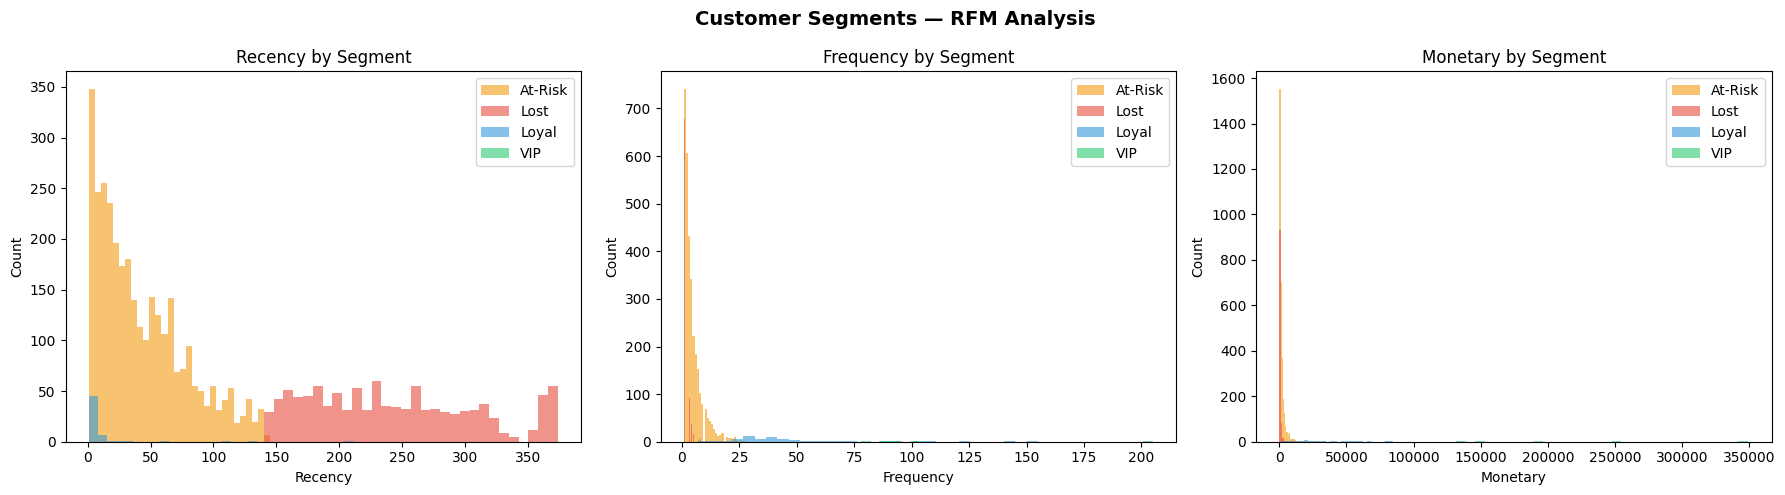

✅ Segments visualized!


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Customer Segments — RFM Analysis', fontsize=14, fontweight='bold')

colors = {'VIP': '#2ecc71', 'At-Risk': '#f39c12', 'Lost': '#e74c3c', 'Loyal': '#3498db'}

for ax, feature in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    for segment, group in rfm.groupby('Segment'):
        ax.hist(group[feature], bins=30, alpha=0.6,
                label=segment, color=colors[segment])
    ax.set_title(f'{feature} by Segment')
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.savefig('segments.png', dpi=150)
plt.show()
print("✅ Segments visualized!")

In [11]:
# Aggregate at product level
product = df.groupby('StockCode').agg(
    TotalQuantity  = ('Quantity', 'sum'),
    TotalRevenue   = ('TotalSpend', 'sum'),
    NumOrders      = ('Invoice', 'nunique'),
    NumCustomers   = ('Customer ID', 'nunique'),
    AvgPrice       = ('Price', 'mean')
).reset_index()

# Define high demand: top 33% by quantity sold
threshold = product['TotalQuantity'].quantile(0.67)
product['HighDemand'] = (product['TotalQuantity'] >= threshold).astype(int)

print("Product table shape:", product.shape)
print(product.head(10))
print("\nDemand Distribution:")
print(product['HighDemand'].value_counts())
print("\nThreshold (min quantity for high demand):", threshold)

Product table shape: (4017, 7)
  StockCode  TotalQuantity  TotalRevenue  NumOrders  NumCustomers  AvgPrice  \
0     10002           7801       6061.97        258           153  0.839813   
1     10080             12         10.20          5             4  0.850000   
2     10109              4          1.68          1             1  0.420000   
3     10120            471         98.91         36            33  0.210000   
4     10125            790        671.50         63            50  0.850000   
5     10133            967        799.85         88            68  0.845568   
6     10134            614        704.80         48            44  1.242692   
7     10135           1982       2302.70        136           108  1.244453   
8     10138            247        103.74         16            14  0.420000   
9     11001           3073       4743.69        120            93  1.663889   

   HighDemand  
0           1  
1           0  
2           0  
3           0  
4           0  
5  

In [12]:
X = product[['TotalRevenue', 'NumOrders', 'NumCustomers', 'AvgPrice']]
y = product['HighDemand']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

demand_scaler = StandardScaler()
X_train_scaled = demand_scaler.fit_transform(X_train)
X_test_scaled  = demand_scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("✅ Ready for modelling!")

Training set: (3213, 4)
Testing set: (804, 4)
✅ Ready for modelling!


In [13]:
# Model 1: Logistic Regression
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

# Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
rf_pred = rf.predict(X_test_scaled)

# Model 3: KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

print("=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

print("=== KNN ===")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred))

=== Logistic Regression ===
Accuracy: 0.9079601990049752
              precision    recall  f1-score   support

           0       0.89      0.98      0.93       526
           1       0.96      0.77      0.85       278

    accuracy                           0.91       804
   macro avg       0.92      0.88      0.89       804
weighted avg       0.91      0.91      0.91       804

=== Random Forest ===
Accuracy: 0.9502487562189055
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       526
           1       0.94      0.91      0.93       278

    accuracy                           0.95       804
   macro avg       0.95      0.94      0.94       804
weighted avg       0.95      0.95      0.95       804

=== KNN ===
Accuracy: 0.9291044776119403
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       526
           1       0.93      0.86      0.89       278

    accuracy                     

In [14]:
# Logistic Regression tuning
lr_params = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear']}
lr_grid = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), lr_params, cv=5, scoring='f1')
lr_grid.fit(X_train_scaled, y_train)
print("=== Logistic Regression ===")
print("Best Params:", lr_grid.best_params_)
print("Best F1:", lr_grid.best_score_)

# Random Forest tuning
rf_params = {'n_estimators': [50, 100, 200], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='f1')
rf_grid.fit(X_train_scaled, y_train)
print("\n=== Random Forest ===")
print("Best Params:", rf_grid.best_params_)
print("Best F1:", rf_grid.best_score_)

# KNN tuning
knn_params = {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='f1')
knn_grid.fit(X_train_scaled, y_train)
print("\n=== KNN ===")
print("Best Params:", knn_grid.best_params_)
print("Best F1:", knn_grid.best_score_)

print("\n✅ Tuning done!")

=== Logistic Regression ===
Best Params: {'C': 100, 'solver': 'liblinear'}
Best F1: 0.9013457124364319

=== Random Forest ===
Best Params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best F1: 0.9423755750101875

=== KNN ===
Best Params: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best F1: 0.9206525150287534

✅ Tuning done!


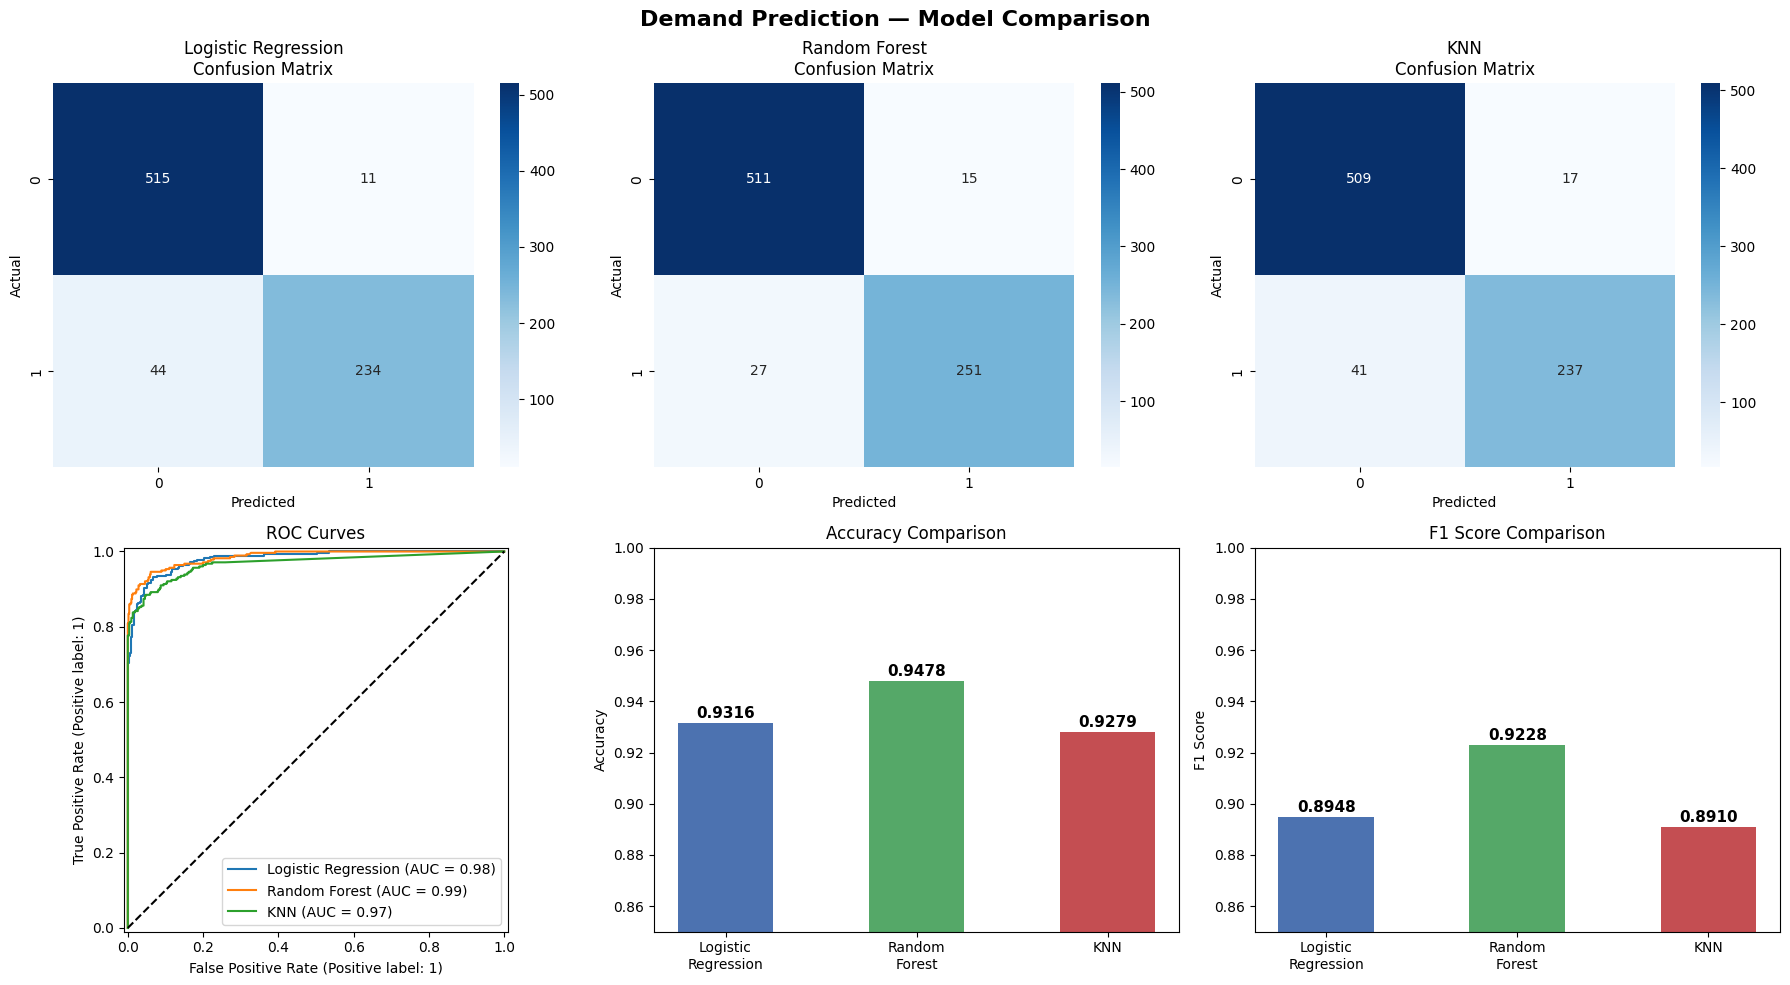

✅ Plots saved!


In [15]:
# Retrain with best parameters
best_lr  = lr_grid.best_estimator_
best_rf  = rf_grid.best_estimator_
best_knn = knn_grid.best_estimator_

best_lr_pred  = best_lr.predict(X_test_scaled)
best_rf_pred  = best_rf.predict(X_test_scaled)
best_knn_pred = best_knn.predict(X_test_scaled)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Demand Prediction — Model Comparison', fontsize=16, fontweight='bold')

# Confusion Matrices
models_pred = {
    'Logistic Regression': best_lr_pred,
    'Random Forest':       best_rf_pred,
    'KNN':                 best_knn_pred
}

for i, (name, pred) in enumerate(models_pred.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, i])
    axes[0, i].set_title(f'{name}\nConfusion Matrix')
    axes[0, i].set_xlabel('Predicted')
    axes[0, i].set_ylabel('Actual')

# ROC Curves
model_objects = {
    'Logistic Regression': best_lr,
    'Random Forest':       best_rf,
    'KNN':                 best_knn
}
for name, model in model_objects.items():
    RocCurveDisplay.from_estimator(model, X_test_scaled, y_test,
                                   ax=axes[1, 0], name=name)
axes[1, 0].set_title('ROC Curves')
axes[1, 0].plot([0, 1], [0, 1], 'k--')

# Accuracy Bar Chart
model_names = ['Logistic\nRegression', 'Random\nForest', 'KNN']
accuracies = [
    accuracy_score(y_test, best_lr_pred),
    accuracy_score(y_test, best_rf_pred),
    accuracy_score(y_test, best_knn_pred)
]
bars1 = axes[1, 1].bar(model_names, accuracies, color=['#4C72B0', '#55A868', '#C44E52'], width=0.5)
axes[1, 1].set_ylim(0.85, 1.0)
axes[1, 1].set_title('Accuracy Comparison')
axes[1, 1].set_ylabel('Accuracy')
for bar, val in zip(bars1, accuracies):
    axes[1, 1].text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.002,
                    f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

# F1 Bar Chart
f1_scores = [
    f1_score(y_test, best_lr_pred),
    f1_score(y_test, best_rf_pred),
    f1_score(y_test, best_knn_pred)
]
bars2 = axes[1, 2].bar(model_names, f1_scores, color=['#4C72B0', '#55A868', '#C44E52'], width=0.5)
axes[1, 2].set_ylim(0.85, 1.0)
axes[1, 2].set_title('F1 Score Comparison')
axes[1, 2].set_ylabel('F1 Score')
for bar, val in zip(bars2, f1_scores):
    axes[1, 2].text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.002,
                    f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('demand_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plots saved!")

In [ ]:
# New unseen products for inference
new_products = pd.DataFrame({
    'TotalRevenue':  [150,   85000,  500,   12000,  30],
    'NumOrders':     [5,     300,    20,    150,    2],
    'NumCustomers':  [4,     250,    18,    120,    2],
    'AvgPrice':      [0.85,  2.50,   1.20,  3.00,   0.42]
})

new_scaled = demand_scaler.transform(new_products)
predictions = best_rf.predict(new_scaled)
probabilities = best_rf.predict_proba(new_scaled)

new_products['Prediction'] = predictions
new_products['High Demand Probability %'] = (probabilities[:, 1] * 100).round(1)
new_products['Status'] = new_products['Prediction'].map({0: '📦 Low Demand', 1: '🔥 High Demand'})

print("=== Demand Inference on New Products ===\n")
print(new_products.to_string(index=False))

=== Demand Inference on New Products ===

 TotalRevenue  NumOrders  NumCustomers  AvgPrice  Prediction  High Demand Probability %        Status
          150          5             4      0.85           0                        3.0  📦 Low Demand
        85000        300           250      2.50           1                      100.0 🔥 High Demand
          500         20            18      1.20           0                       25.9  📦 Low Demand
        12000        150           120      3.00           1                       95.0 🔥 High Demand
           30          2             2      0.42           0                        0.0  📦 Low Demand
